# 11 · Books, data starvation, held positions, and a simulation of the intervals

Plan §16.11–§16.14, specified 2026-11-05 and revised 2026-11-06 before any of them ran. All are descriptive and exploratory; only SPX 2020's verdict is a pre-registered test. The rules are those of the preamble to §16.11:
- R1 (Black–Scholes), R2 (Hull–White), R3 (Ruf–Wang fixed), R4 (Ruf–Wang fitted), R6 (delta–vega–vanna), R9 (LightGBM on δ), P0 (a constant correction);
- on SPX, Heston's H_model, H_mv and H_fit.

Each is refitted monthly on the trailing 12 months unless stated. The intervals are session-block bootstraps, as everywhere in the project.

In [1]:
import sys, json
from pathlib import Path
import numpy as np, pandas as pd, matplotlib.pyplot as plt
ROOT = Path.cwd().parent if Path.cwd().name == "notebooks" else Path.cwd()
sys.path.insert(0, str(ROOT / "src"))
R = ROOT / "results"
pd.set_option("display.width", 160); pd.set_option("display.max_columns", 30)
plt.rcParams.update({"figure.figsize": (9, 4), "axes.grid": True, "grid.alpha": 0.3})
U = [u for u in ("spx", "spy") if (R / "extensions" / u).exists()]
U

['spx', 'spy']

## 1. Books (§16.14)

The Gain pools each option's squared error as if each were hedged alone. A dealer hedges the net delta of a book, where option-specific errors diversify away and the day's shared move adds up.

Four books are formed each session from day-one information: all calls; all puts; out-of-the-money puts and calls (long volatility); and a risk reversal, long OTM calls and short OTM puts, as the control. A book's error is the mean of its options' errors.

In [2]:
for u in U:
    m = pd.read_csv(R / "extensions" / u / "books_median_yearly_gain.csv")
    m = m[(m.base == "R1") & m.rule.isin(["R2", "P0", "R3", "R4", "R9", "H_mv"])]
    print(u.upper(), "median yearly Gain over Black-Scholes, 2011-2023")
    display(m.pivot_table(index=["book", "rule"], columns="measure", values="median_yearly_gain").round(3))

SPX median yearly Gain over Black-Scholes, 2011-2023


measure              book  per_option
book          rule                   
calls         H_mv -0.264      -0.340
              P0    0.224       0.151
              R2    0.221       0.151
              R3    0.250       0.125
              R4    0.210       0.120
              R9    0.222       0.151
long_vol      H_mv -0.079      -0.217
              P0    0.230       0.158
              R2    0.217       0.162
              R3    0.214       0.150
              R4    0.180       0.120
              R9    0.224       0.162
puts          H_mv -0.034      -0.144
              P0    0.180       0.120
              R2    0.173       0.120
              R3    0.203       0.099
              R4    0.151       0.081
              R9    0.176       0.122
risk_reversal H_mv  0.053      -0.217
              P0    0.061       0.158
              R2    0.041       0.162
              R3    0.052       0.150
              R4    0.039       0.120
              R9    0.054       0.162

SPY median yearly Gain over Black-Scholes, 2011-2023


measure              book  per_option
book          rule                   
calls         P0    0.117       0.073
              R2    0.114       0.085
              R3    0.100      -0.035
              R4    0.107       0.039
              R9    0.114       0.086
long_vol      P0    0.263       0.184
              R2    0.254       0.187
              R3    0.241       0.153
              R4    0.186       0.135
              R9    0.255       0.192
puts          P0    0.288       0.213
              R2    0.287       0.215
              R3    0.269       0.183
              R4    0.277       0.170
              R9    0.287       0.217
risk_reversal P0    0.067       0.184
              R2    0.063       0.187
              R3    0.048       0.153
              R4    0.109       0.135
              R9    0.072       0.192

In [3]:
for u in U:
    s = pd.read_csv(R / "extensions" / u / "books_common_share.csv")
    print(u.upper(), "share of the per-option squared error that survives averaging (median over years)")
    display(s.groupby("book").common_share_R1.median().round(3))

SPX share of the per-option squared error that survives averaging (median over years)


book
calls            0.711
long_vol         0.687
puts             0.693
risk_reversal    0.119
Name: common_share_R1, dtype: float64

SPY share of the per-option squared error that survives averaging (median over years)


book
calls            0.634
long_vol         0.647
puts             0.671
risk_reversal    0.109
Name: common_share_R1, dtype: float64

In [4]:
for u in U:
    b = pd.read_csv(R / "extensions" / u / "books_by_year.csv")
    x = b[(b.rule == "R2") & (b.base == "R1") & b.year.isin([2020, 2022])]
    print(u.upper(), "R2 over R1 in 2020 and 2022")
    display(x.pivot_table(index=["year", "book"], columns="measure", values=["gain", "lo", "hi"]).round(3))

SPX R2 over R1 in 2020 and 2022


gain                hi                lo           
measure              book per_option   book per_option   book per_option
year book                                                               
2020 calls          0.233      0.185  0.548      0.463 -0.551     -0.357
     long_vol       0.217      0.201  0.563      0.505 -0.624     -0.438
     puts           0.118      0.120  0.511      0.457 -0.585     -0.447
     risk_reversal  0.212      0.201  0.376      0.505 -0.099     -0.438
2022 calls         -0.020      0.002  0.237      0.155 -0.349     -0.186
     long_vol      -0.107     -0.048  0.174      0.122 -0.488     -0.259
     puts          -0.136     -0.058  0.131      0.103 -0.490     -0.263
     risk_reversal -0.143     -0.048  0.025      0.122 -0.329     -0.259

SPY R2 over R1 in 2020 and 2022


gain                hi                lo           
measure              book per_option   book per_option   book per_option
year book                                                               
2020 calls          0.162      0.104  0.496      0.398 -0.474     -0.298
     long_vol       0.240      0.179  0.528      0.452 -0.502     -0.329
     puts           0.283      0.238  0.532      0.477 -0.382     -0.249
     risk_reversal -0.010      0.179  0.290      0.452 -0.338     -0.329
2022 calls          0.064      0.027  0.318      0.197 -0.269     -0.167
     long_vol      -0.025     -0.024  0.249      0.165 -0.408     -0.244
     puts          -0.061     -0.045  0.195      0.149 -0.427     -0.281
     risk_reversal -0.074     -0.024  0.026      0.165 -0.182     -0.244

**Reading (SPX; SPY is the same in direction).**
- **A dealer hedging a book sees more of the Gain than the per-option numbers suggest.** SPX's median yearly Gain of R2 over Black–Scholes is 0.22 on the call book against 0.15 per option, and 0.17 against 0.12 for puts.
- **The reason:** about 70% of an option's squared error survives averaging across a book. That is the day's shared move, which the correction targets; option-specific noise diversifies away.
- **The amplification works both ways:** in 2022 the SPX put book lost 0.14, against 0.06 per option.
- **The risk reversal is the control.** Its volatility exposures cancel, so it keeps 12% of the error, and the corrections gain 0.04.
- **Heston's H_mv loses on books too.**

## 2. Data starvation (§16.13)

**Fewer sessions:** 1-, 2-, 3- and 6-month windows. **Fewer options per session:** 12-month fits on 25%, 5% or 1% of each training session's options, or on 10 or 3 per session and type, with five seeds.

The plan stated the expectation in advance: the information is in the number of sessions, because every option on a day shares that day's index move.

In [5]:
for u in U:
    sp = pd.read_csv(R / "extensions" / u / "starve_seed_spread.csv")
    first = sp.span.iloc[0]
    x = sp[(sp.base == "R1") & sp.rule.isin(["R2", "P0", "R9"]) & (sp.span == first)]
    print(u.upper(), "median yearly Gain over R1,", first, "(median over seeds; min and max for thinning)")
    display(x.pivot_table(index="config", columns=["rule", "cp"], values="median").round(3))
    display(x[x.config.str.startswith(("frac", "k"))].pivot_table(index=["config", "rule"], columns="cp", values=["min", "max"]).round(3))

SPX median yearly Gain over R1, 2011-2023 (median over seeds; min and max for thinning)


rule         P0            R2            R9       
cp            C      P      C      P      C      P
config                                            
W1        0.082  0.028  0.091  0.031  0.089  0.024
W12       0.151  0.120  0.151  0.120  0.151  0.122
W2        0.090  0.034  0.092  0.047  0.093  0.042
W3        0.142  0.104  0.143  0.104  0.143  0.106
W6        0.139  0.134  0.139  0.133  0.139  0.134
frac0.01  0.146  0.122  0.144  0.119  0.137  0.112
frac0.05  0.150  0.121  0.149  0.120  0.146  0.122
frac0.25  0.150  0.120  0.151  0.120  0.151  0.122
k10       0.147  0.135  0.143  0.132  0.143  0.133
k3        0.142  0.134  0.138  0.124  0.135  0.112

max           min       
cp                 C      P      C      P
config   rule                            
frac0.01 P0    0.150  0.139  0.135  0.120
         R2    0.145  0.127  0.132  0.116
         R9    0.146  0.122  0.133  0.092
frac0.05 P0    0.151  0.122  0.146  0.118
         R2    0.150  0.122  0.141  0.110
         R9    0.150  0.123  0.141  0.117
frac0.25 P0    0.151  0.120  0.149  0.120
         R2    0.153  0.121  0.148  0.118
         R9    0.153  0.123  0.148  0.121
k10      P0    0.147  0.138  0.139  0.134
         R2    0.147  0.143  0.138  0.131
         R9    0.145  0.138  0.136  0.131
k3       P0    0.148  0.141  0.135  0.124
         R2    0.140  0.131  0.130  0.120
         R9    0.141  0.122  0.134  0.088

SPY median yearly Gain over R1, 2011-2023 (median over seeds; min and max for thinning)


rule         P0            R2            R9       
cp            C      P      C      P      C      P
config                                            
W1        0.050  0.186  0.051  0.164  0.053  0.165
W12       0.073  0.213  0.085  0.215  0.086  0.217
W2        0.052  0.134  0.074  0.120  0.072  0.121
W3        0.065  0.205  0.080  0.200  0.081  0.199
W6        0.067  0.175  0.069  0.177  0.074  0.179
frac0.01  0.076  0.212  0.077  0.212  0.059  0.177
frac0.05  0.072  0.214  0.087  0.215  0.084  0.215
frac0.25  0.073  0.213  0.086  0.215  0.087  0.217
k10       0.073  0.210  0.080  0.212  0.075  0.193
k3        0.072  0.209  0.070  0.207  0.053  0.156

max           min       
cp                 C      P      C      P
config   rule                            
frac0.01 P0    0.081  0.213  0.068  0.212
         R2    0.087  0.215  0.060  0.211
         R9    0.073  0.187  0.056  0.168
frac0.05 P0    0.078  0.215  0.071  0.213
         R2    0.089  0.216  0.079  0.214
         R9    0.085  0.216  0.077  0.201
frac0.25 P0    0.074  0.214  0.071  0.213
         R2    0.089  0.217  0.085  0.215
         R9    0.089  0.218  0.086  0.217
k10      P0    0.081  0.217  0.070  0.205
         R2    0.089  0.214  0.076  0.205
         R9    0.080  0.196  0.074  0.179
k3       P0    0.078  0.219  0.070  0.207
         R2    0.084  0.213  0.063  0.201
         R9    0.067  0.170  0.047  0.142

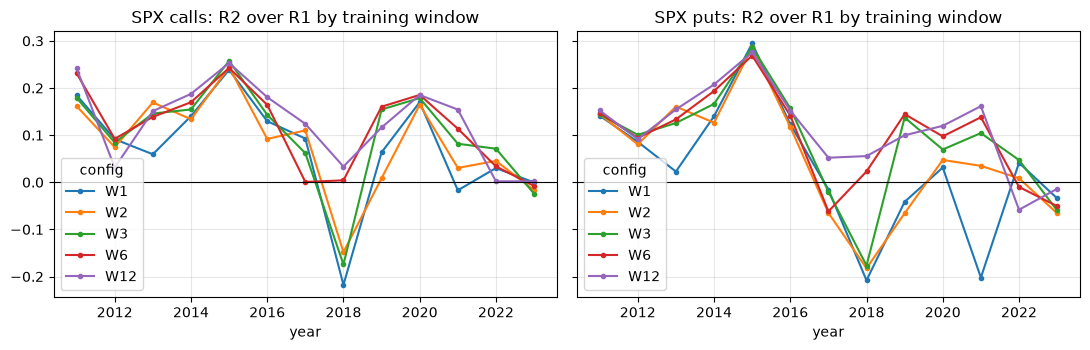

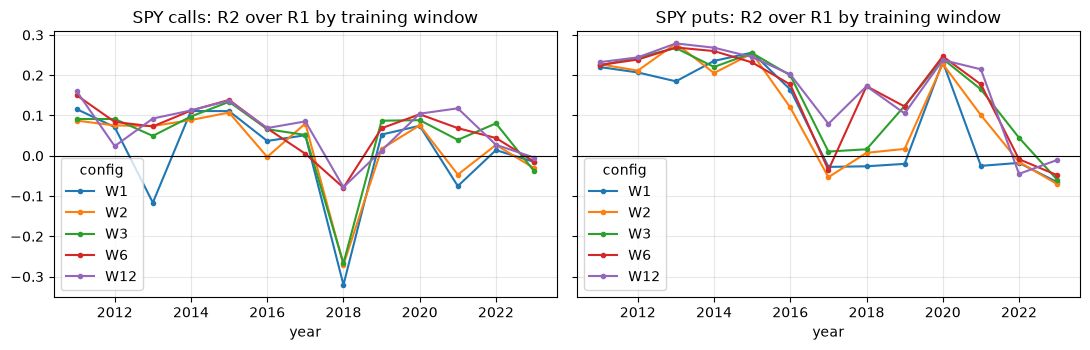

In [6]:
for u in U:
    G = pd.read_csv(R / "extensions" / u / "starve_by_year.csv")
    w = G[(G.rule == "R2") & (G.base == "R1") & G.config.isin(["W1", "W2", "W3", "W6", "W12"])]
    fig, axes = plt.subplots(1, 2, figsize=(11, 3.6), sharey=True)
    for ax, cp in zip(axes, "CP"):
        p = w[w.cp == cp].pivot_table(index="year", columns="config", values="gain")[["W1", "W2", "W3", "W6", "W12"]]
        p.plot(ax=ax, marker="o", ms=3)
        ax.axhline(0, color="k", lw=0.8); ax.set_title(f"{u.upper()} {'calls' if cp == 'C' else 'puts'}: R2 over R1 by training window")
    plt.tight_layout()

**Reading.**
- **The plan's expectation holds: the information is in the number of sessions, not options.**
  - On SPX, three options per session and type keep a median yearly Gain of 0.138 (calls) and 0.124 (puts), against 0.151 and 0.120 with every option. Over five seeds the range is 0.130–0.140 and 0.120–0.131.
  - Windows of one or two months cut the Gain to about 0.09 and 0.03–0.05.
- **Short windows adapt faster to a regime change.** In 2022 a 3-month window gave +0.071 and +0.047, against +0.002 and −0.058 on 12 months. In 2020 the 12-month window was best.
- **No window is best every year:** a long window estimates the level precisely but goes stale; a short one tracks it but is noisy.
- **SPY shows the same.** R9, a tree learner, loses more than R2 when thinned: it needs more data than three linear coefficients.

## 3. Held positions (§16.11)

A path is H one-session hedges in a row on one contract (H = 5 or 10 sessions), re-hedged at every close with that day's ratio, as a desk would do. After the start, the contract is followed whatever its delta, maturity or volume, because dropping it when it leaves the band would select on the outcome.

The path error is the sum of the daily dollar errors, in units of the index level on the start day. The one-session Gain on exactly the same pairs is reported beside it.

In [7]:
for u in U:
    f = R / "extensions" / u / "paths_gains.csv"
    if not f.exists():
        continue
    G = pd.read_csv(f)
    x = G[(G.subset == "all") & (G.base == "R1") & G.rule.isin(["R2", "P0", "R3", "R4", "R9"]) & ~G.period.str.fullmatch(r"\d{4}")]
    print(u.upper(), "pooled periods: path Gain against the one-session Gain on the same pairs")
    display(x.pivot_table(index=["H", "period", "rule"], columns=["measure", "cp"], values="gain").round(3))

SPX pooled periods: path Gain against the one-session Gain on the same pairs


measure           one_session          path       
cp                          C      P      C      P
H  period    rule                                 
5  2011-2019 P0         0.137  0.121  0.189  0.203
             R2         0.133  0.118  0.185  0.200
             R3         0.146  0.128  0.155  0.148
             R4         0.096  0.079  0.123  0.113
             R9         0.137  0.121  0.187  0.203
   2021-2023 P0         0.044  0.012 -0.005 -0.104
             R2         0.047  0.012 -0.002 -0.108
             R3        -0.064 -0.066 -0.165 -0.183
             R4         0.043  0.001  0.000 -0.076
             R9         0.047  0.014 -0.001 -0.102
10 2011-2019 P0         0.152  0.125  0.243  0.343
             R2         0.149  0.120  0.241  0.338
             R3         0.152  0.130  0.151  0.216
             R4         0.099  0.078  0.140  0.203
             R9         0.152  0.125  0.243  0.341
   2021-2023 P0         0.043 -0.003  0.032 -0.054
             R2         0.048 -0.002  0.018 -0.066
             R3        -0.063 -0.088 -0.176 -0.140
             R4         0.047 -0.015 -0.012 -0.037
             R9         0.047 -0.000  0.028 -0.058

SPY pooled periods: path Gain against the one-session Gain on the same pairs


measure           one_session          path       
cp                          C      P      C      P
H  period    rule                                 
5  2011-2019 P0         0.081  0.203  0.164  0.307
             R2         0.080  0.201  0.168  0.296
             R3         0.090  0.200  0.112  0.247
             R4         0.032  0.183  0.076  0.247
             R9         0.083  0.203  0.170  0.299
   2021-2023 P0         0.065  0.066  0.059  0.042
             R2         0.066  0.069  0.060  0.048
             R3        -0.050  0.028 -0.084  0.027
             R4         0.029  0.063  0.039  0.071
             R9         0.072  0.072  0.066  0.051
10 2011-2019 P0         0.075  0.203  0.215  0.379
             R2         0.078  0.201  0.224  0.368
             R3         0.078  0.203  0.135  0.269
             R4         0.031  0.185  0.124  0.282
             R9         0.081  0.204  0.224  0.370
   2021-2023 P0         0.077  0.051  0.100  0.052
             R2         0.077  0.053  0.101  0.046
             R3        -0.048  0.012 -0.110  0.002
             R4         0.038  0.046  0.065  0.061
             R9         0.084  0.056  0.105  0.051

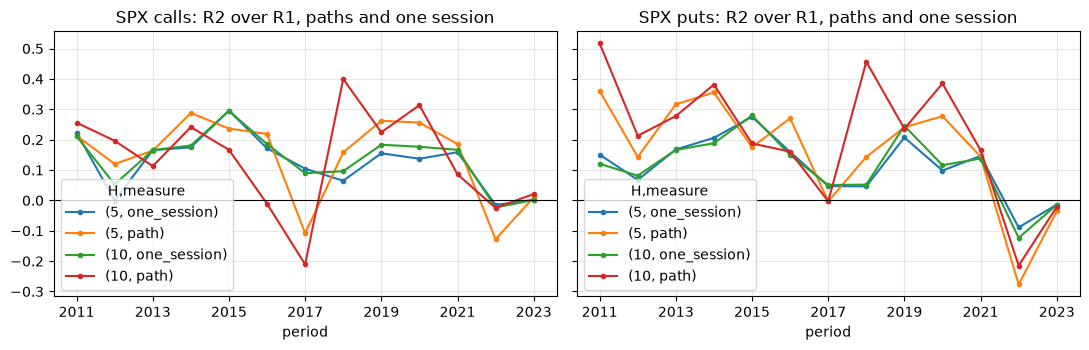

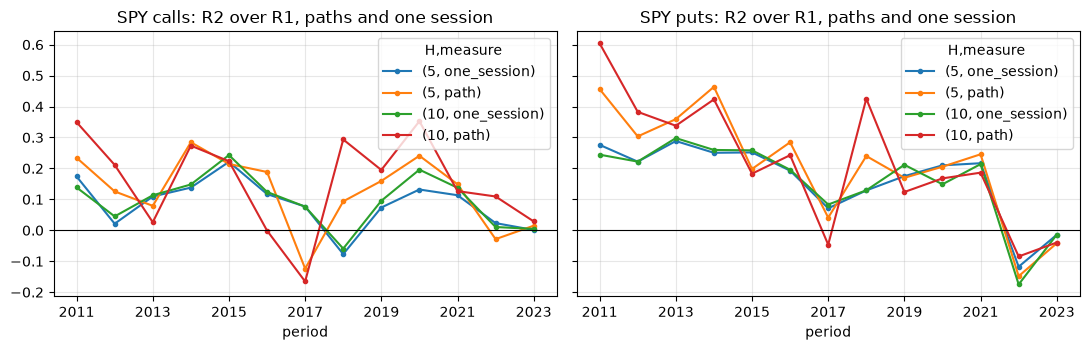

In [8]:
for u in U:
    f = R / "extensions" / u / "paths_gains.csv"
    if not f.exists():
        continue
    G = pd.read_csv(f)
    y = G[(G.subset == "all") & (G.base == "R1") & (G.rule == "R2") & G.period.str.fullmatch(r"\d{4}")]
    fig, axes = plt.subplots(1, 2, figsize=(11, 3.6), sharey=True)
    for ax, cp in zip(axes, "CP"):
        p = y[y.cp == cp].pivot_table(index="period", columns=["H", "measure"], values="gain")
        p.plot(ax=ax, marker="o", ms=3)
        ax.axhline(0, color="k", lw=0.8); ax.set_title(f"{u.upper()} {'calls' if cp == 'C' else 'puts'}: R2 over R1, paths and one session")
    plt.tight_layout()

In [9]:
for u in U:
    f = R / "extensions" / u / "paths_mean_error.csv"
    if not f.exists():
        continue
    M = pd.read_csv(f)
    print(u.upper(), "mean path error and its difference from Black-Scholes (units of the start-day index level)")
    display(M[(M.subset == "all") & M.rule.isin(["R2", "P0", "R3", "R4"]) & ~M.period.str.fullmatch(r"\d{4}")]
            .pivot_table(index=["H", "period", "rule"], columns="cp", values=["diff_vs_R1", "diff_lo", "diff_hi"]).round(6))
    display(pd.read_csv(R / "extensions" / u / "paths_attrition.csv").groupby("H")[["eligible", "complete", "left_band"]].sum())
    display(pd.read_csv(R / "extensions" / u / "paths_day0_check.csv").max_abs_diff.max())

SPX mean path error and its difference from Black-Scholes (units of the start-day index level)


diff_hi             diff_lo           diff_vs_R1          
cp                        C         P         C         P          C         P
H  period    rule                                                             
5  2011-2019 P0    0.000176  0.000202 -0.000021 -0.000024   0.000084  0.000096
             R2    0.000183  0.000205 -0.000017 -0.000029   0.000088  0.000096
             R3    0.000173  0.000163 -0.000008  0.000020   0.000086  0.000096
             R4    0.000153  0.000163 -0.000018  0.000001   0.000072  0.000088
   2021-2023 P0    0.000174  0.000186 -0.000132 -0.000136   0.000024  0.000028
             R2    0.000183  0.000195 -0.000135 -0.000142   0.000025  0.000029
             R3    0.000244  0.000214 -0.000135 -0.000092   0.000057  0.000066
             R4    0.000142  0.000152 -0.000113 -0.000093   0.000015  0.000033
10 2011-2019 P0    0.000325  0.000363 -0.000065 -0.000081   0.000142  0.000156
             R2    0.000336  0.000367 -0.000058 -0.000093   0.000151  0.000152
             R3    0.000306  0.000304 -0.000067  0.000055   0.000126  0.000185
             R4    0.000276  0.000307 -0.000071  0.000026   0.000112  0.000172
   2021-2023 P0    0.000329  0.000339 -0.000226 -0.000228   0.000054  0.000059
             R2    0.000348  0.000357 -0.000233 -0.000237   0.000060  0.000065
             R3    0.000494  0.000430 -0.000225 -0.000109   0.000137  0.000171
             R4    0.000268  0.000280 -0.000201 -0.000142   0.000032  0.000074

,eligible,complete,left_band
H,,,
5,1538296,1446244,217964
10,733181,651833,163650


np.float64(0.0)

SPY mean path error and its difference from Black-Scholes (units of the start-day index level)


diff_hi             diff_lo           diff_vs_R1          
cp                        C         P         C         P          C         P
H  period    rule                                                             
5  2011-2019 P0    0.000166  0.000261 -0.000028  0.000051   0.000075  0.000161
             R2    0.000174  0.000263 -0.000021  0.000049   0.000082  0.000162
             R3    0.000184  0.000197 -0.000009  0.000060   0.000090  0.000132
             R4    0.000106  0.000222 -0.000034  0.000061   0.000039  0.000146
   2021-2023 P0    0.000186  0.000318 -0.000049 -0.000021   0.000072  0.000151
             R2    0.000192  0.000334 -0.000054 -0.000021   0.000073  0.000159
             R3    0.000327  0.000269 -0.000002  0.000046   0.000165  0.000159
             R4    0.000138  0.000247 -0.000028  0.000023   0.000054  0.000138
10 2011-2019 P0    0.000346  0.000504 -0.000052  0.000102   0.000154  0.000311
             R2    0.000361  0.000503 -0.000041  0.000098   0.000168  0.000309
             R3    0.000325  0.000379 -0.000036  0.000139   0.000151  0.000262
             R4    0.000212  0.000419 -0.000056  0.000150   0.000083  0.000288
   2021-2023 P0    0.000339  0.000592 -0.000050  0.000052   0.000149  0.000325
             R2    0.000349  0.000614 -0.000055  0.000051   0.000152  0.000337
             R3    0.000642  0.000552  0.000063  0.000170   0.000360  0.000364
             R4    0.000256  0.000487 -0.000003  0.000116   0.000127  0.000305

,eligible,complete,left_band
H,,,
5,1080222,575114,32312
10,522621,182065,16896


np.float64(0.0)

**Reading (SPX).**
- **Checks.**
  - On 2,271,477 first days the path code's error equals the walk-forward's exactly.
  - 94% (5 sessions) and 89% (10 sessions) of eligible paths complete.
  - 15% and 25% of completed paths leave the band at least once. They would have been lost had positions been dropped there, and on the in-band-only subset the Gain is smaller.
- **On real SPX quotes the Gain grows with the holding period.** In 2011–2019, R2 removes 0.185 / 0.200 of a 5-session position's squared error and 0.241 / 0.338 of a 10-session one's, against 0.133 / 0.118 one session at a time.
  - In 2020: 0.256 / 0.277 (5 sessions) and 0.313 / 0.385 (10).
  - Two reasons: quote noise in the mids telescopes away in a path's sum, and the spot–volatility move accumulates over a multi-day sell-off.
- **Losses grow too:** 2021–2023 puts −0.108 over 5 sessions.
- **The expected-P&L cost of the correction is about 1 bp of the index over 5 sessions, and not significant,** so the Sharpe-ratio argument's assumption roughly holds.
- **SPY** shows the same growth in 2011–2019. But its Greeks exist only for first-day candidates, so its paths are restricted to traded days with at least 14 days to expiry (§15).

## 4. Do the intervals cover the truth? A simulation (§16.12)

A regression-level market with a known true Gain is calibrated to 2019; the whole test is repeated 1,000 times per effect size κ (κ = 1 is 2019's effect). Three scenarios are run: stationary GARCH years; a calm path (2018 → 2019); and 2020's own volatility path (2019 → 2020).

Coverage is the share of 95% intervals that contain the true conditional Gain. The H1 pass rate is the share of replications in which both lower bounds are above 0. Design and caveats: `notes/background/coverage-simulation.md`.

In [10]:
C = pd.read_csv(R / "simulation/coverage.csv")
a = C[C.subset == "all"]
display(a[a.cp.isin(["C", "P"])].pivot_table(index=["scenario", "kappa"], columns="cp",
        values=["coverage_cond", "bias_cond", "median_width", "mean_G_cond"]).round(3))
display(a[a.h1_pass_rate.notna()].pivot_table(index="kappa", columns="scenario", values="h1_pass_rate").round(3))
display(a.groupby("scenario").median_top10_share.median().round(3))

bias_cond        coverage_cond        mean_G_cond        median_width       
cp                       C      P             C      P           C      P            C      P
scenario   kappa                                                                             
calm       0.0      -0.011 -0.005         0.904  0.902      -0.073 -0.062        0.067  0.054
           0.5      -0.007 -0.002         0.884  0.892      -0.027 -0.009        0.143  0.133
           1.0       0.001  0.003         0.876  0.878       0.090  0.123        0.218  0.205
           1.5       0.009  0.008         0.855  0.879       0.236  0.279        0.232  0.217
           2.0       0.015  0.011         0.838  0.870       0.376  0.423        0.212  0.196
path2020   0.0      -0.014 -0.012         0.883  0.883      -0.008 -0.007        0.066  0.059
           0.5      -0.006 -0.002         0.856  0.850       0.000  0.003        0.170  0.173
           1.0       0.016  0.024         0.794  0.780       0.022  0.033        0.309  0.306
           1.5       0.046  0.057         0.698  0.676       0.057  0.079        0.404  0.379
           2.0       0.078  0.089         0.619  0.574       0.101  0.136        0.436  0.400
stationary 0.0      -0.005 -0.004         0.911  0.913      -0.033 -0.028        0.039  0.033
           0.5       0.001  0.001         0.898  0.904       0.007  0.019        0.119  0.113
           1.0       0.014  0.011         0.862  0.873       0.111  0.135        0.185  0.175
           1.5       0.027  0.021         0.826  0.841       0.239  0.275        0.203  0.187
           2.0       0.036  0.028         0.783  0.804       0.364  0.406        0.191  0.175

scenario,calm,path2020,stationary
kappa,,,
0.0,0.012,0.023,0.010
0.5,0.282,0.120,0.364
1.0,0.620,0.252,0.715
1.5,0.814,0.391,0.849
2.0,0.907,0.514,0.906


scenario
calm          0.333
path2020      0.694
stationary    0.298
Name: median_top10_share, dtype: float64

**Reading.**
- **The 95% intervals undercover everywhere, and worst in a year like 2020.**
  - On 2020's own volatility path, at 2019's effect size, they contain the true conditional Gain 78–79% of the time; at twice that effect, 57–62%.
  - In stationary years at 2019's effect, coverage is 86–87%.
- **H1 would pass only 25% of the time on 2020's path at 2019's effect size,** against 72% in stationary years. With no effect it passes 1–2% of the time.
- **On 2020's path the true conditional Gain of 2019's effect is only about 0.02–0.03:** the crash days' gamma and volatility noise swamp the signal.
- **So "Inconclusive" was the likely outcome of a crash test year** even if the rule worked as it did in 2019, and the real 2020 intervals, wide as they are, probably understate the uncertainty.
- **Caveats:**
  - the calibration uses a gamma scale (0.46) and a noise rescale, both fitted to 2019;
  - the spot–volatility relation is stationary in the simulation.

Details: `notes/background/coverage-simulation.md` (private notes).